<a href="https://colab.research.google.com/github/Douaa-Nozomi/cytokine-analysis/blob/main/tp2_open_science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(seed=2025)
plt.rcParams['figure.figsize'] = (7, 4)


In [ ]:
conc = np.array([0, 2, 4, 6, 8, 10]) # μg/mL
absorbance = 0.0512 * conc + 0.004 + rng.normal(0, 0.008, conc.size)
absorbance = absorbance.round(3)
pd.DataFrame({"concentration (μg/mL)": conc, "absorbance": absorbance})

,concentration (μg/mL),absorbance
0,0,-0.014
1,2,0.107
2,4,0.204
3,6,0.302
4,8,0.394
5,10,0.522


In [ ]:

# 1) Droite de régression
pente, ordonnee = np.polyfit(conc, absorbance, 1)
# 2) Coefficient de détermination R²
A_calc = pente * conc + ordonnee # absorbance calculée par la droite
ss_res = np.sum((absorbance - A_calc) ** 2) # écarts entre mesure et droite
ss_tot = np.sum((absorbance- np.mean(absorbance)) ** 2) # écarts entre mesure et moyenne
R2 = 1 - ss_res / ss_tot
# 3) Affichage
print(f"pente = {pente:.4f} | ordonnée = {ordonnee:.4f} | R² = {R2:.4f}")

pente = 0.0520 | ordonnée = -0.0074 | R² = 0.9975


Dans la cuvette : 6.11 μg/mL | Solution mère : 30.5 μg/mL


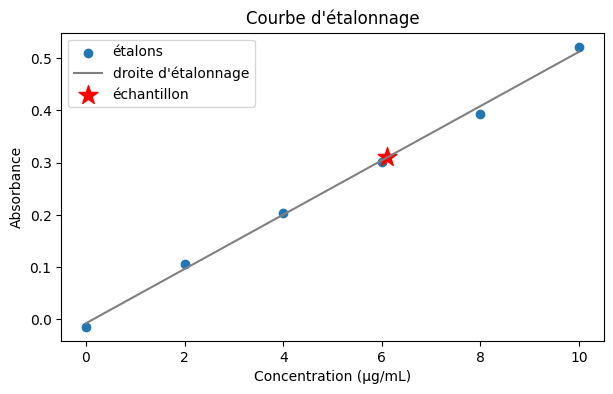

In [ ]:
A_inconnu = 0.310
dilution = 5
C_cuvette = (A_inconnu - ordonnee) / pente    # concentration dans la cuvette (μg/mL)
C_mere = C_cuvette * dilution # concentration de la solution mère (μg/mL)
print(f"Dans la cuvette : {C_cuvette:.2f} μg/mL | Solution mère : {C_mere:.1f} μg/mL")
# Graphique
plt.scatter(conc, absorbance, label="étalons")
plt.plot(conc, A_calc, color="gray", label="droite d'étalonnage")
# marker: l'étoile s'écrit "*"
plt.scatter(C_cuvette, A_inconnu, marker="*", s=200, color="red", label="échantillon")
plt.title("Courbe d'étalonnage")
plt.xlabel("Concentration (μg/mL)")
plt.ylabel("Absorbance")
plt.legend()
plt.show()

Votre repence:Q1=a ,Q2=b ,Q3=a

In [ ]:
def michaelis(S, Vmax, Km):
 return Vmax * S / (Km + S)
S = np.array([0.5, 1, 2, 5, 10, 20, 50, 100]) # mM
# mM, concentration de l'inhibiteur
I = 10
v_sans = (michaelis(S, 120, 8) * np.random.normal(1, 0.04, S.size)).round(1)
v_avec = (michaelis(S, 120, 8 * (1 + I / 5)) * np.random.normal(1, 0.04, S.size)).round(1)
pd.DataFrame({"S (mM)": S, "v sans inhibiteur": v_sans, "v avec inhibiteur": v_avec})

,S (mM),v sans inhibiteur,v avec inhibiteur
0,0.5,6.7,2.2
1,1.0,12.5,4.6
2,2.0,23.7,9.1
3,5.0,46.3,19.9
4,10.0,61.5,35.3
5,20.0,83.4,55.0
6,50.0,102.2,82.3
7,100.0,111.6,95.8


In [ ]:
def hill(logC, Emin, Emax, logEC50, n):
  return Emin + (Emax - Emin) / (1 + 10 ** ((logEC50 - logC) * n))
logC = np.arange(-9, -3.5, 0.5) # log10 de la concentration (M)
effet_A = (hill(logC, 2, 98, -7.0, 1.0) + rng.normal(0, 3, logC.size)).round(1)
effet_B = (hill(logC, 2, 98, -6.3, 1.0) + rng.normal(0, 3, logC.size)).round(1)
pd.DataFrame({"logC": logC, "effet A (%)": effet_A, "effet B (%)": effet_B})

,logC,effet A (%),effet B (%)
0,-9.0,0.7,11.0
1,-8.5,5.7,0.6
2,-8.0,12.8,7.7
3,-7.5,25.9,2.7
4,-7.0,49.4,16.8
5,-6.5,76.9,34.8
6,-6.0,90.8,66.5
7,-5.5,96.9,90.3
8,-5.0,92.1,90.7
9,-4.5,96.5,98.9


In [ ]:
# Composé A
pA, _ = curve_fit(hill, logC, effet_A, p0=[0, 100, -7, 1])
EC50_A = 10 ** pA[2] * 1e9 # en nM
# Composé B : même chose avec la deuxième série d'effets
pB, _ = curve_fit(hill, logC, effet_B, p0=[0, 100, -7, 1])
# en nM (indice : le logEC50 est le 3e paramètre, pB[2])
EC50_B = 10 ** pB[2] * 1e9
tableau = pd.DataFrame({"Emax": [pA[1], pB[1]], "pEC50": [-pA[2], -pB[2]],
"EC50 (nM)": [EC50_A, EC50_B], "pente de Hill": [pA[3], pB[3]]},
index=["Composé A", "Composé B"]).round(2)

NameError: name 'curve_fit' is not defined